# 09 · Davisson–Germer (1927) và từng electron / and individual electrons

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JasonDE03/sophon/blob/main/lab/09_davisson_germer.ipynb)

Từ bước sóng de Broglie đến gờ nhiễu xạ trên niken, vân tích lại từng electron, rồi vòng truyền qua màng mỏng. Chạy từ trên xuống; không tải dữ liệu.
*From de Broglie's wavelength to nickel diffraction, single-electron buildup, and transmission rings. Run from top to bottom; no data downloads.*


## 1. Mạng hàng nguyên tử bề mặt / Surface-row grating

Electron qua điện thế $V$ có $eV=p^2/(2m_e)$, nên $\lambda=h/\sqrt{2m_e eV}$. Với chùm tới vuông góc, điều kiện bậc một là $d\sin\theta=\lambda$, $d=0{,}215$ nm là **khoảng cách giữa các hàng nguyên tử trên mặt Ni(111)**, không phải khoảng cách giữa các mặt tinh thể. Góc $\theta$ tính từ hướng ngược chùm tới: thẳng ngược lên là $0^\circ$.
*Nonrelativistic electrons have the wavelength above. Here d is the spacing of surface atom rows, not an interplanar spacing; θ starts in the straight-back direction.*

Ở 54 V, dự đoán $50{,}9^\circ$ gần góc đo $50^\circ$. Điều kiện hàng bề mặt cho hướng tăng cường; nó không tự cho cường độ theo điện thế ([Davisson–Germer, 1927](https://doi.org/10.1103/PhysRev.30.705)).
*At 54 V, the predicted 50.9° is close to the measured 50°. The surface-row condition predicts a direction, not its voltage-dependent intensity.*


54 V: wavelength = 0.166895 nm; predicted angle = 50.919 deg; measured = 50 deg
First-order threshold: V >= 32.539 V


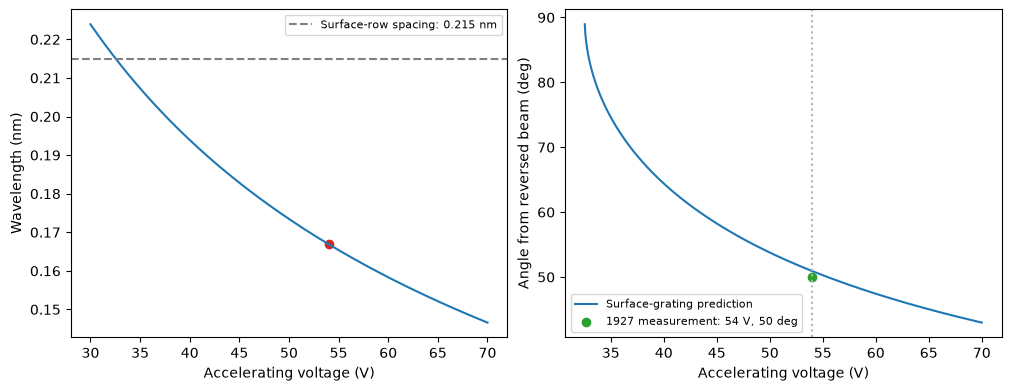

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import h, e
from scipy.integrate import quad

# Match sims/davisson.js; all underlying constants are SI.
m_e = 9.1093837015e-31
d_nm = 0.215

def wavelength_nm(voltage):
    return h / np.sqrt(2 * m_e * e * np.asarray(voltage)) * 1e9

def peak_angle_deg(voltage, d=d_nm):
    ratio = wavelength_nm(voltage) / d
    return np.degrees(np.arcsin(np.where(ratio <= 1, ratio, np.nan)))

voltage = np.linspace(30, 70, 801)
lam54 = float(wavelength_nm(54))
theta54 = float(peak_angle_deg(54))
assert abs(lam54 / 0.1669 - 1) < 0.005
assert abs(theta54 - 50.9) < 0.2
assert np.isnan(peak_angle_deg(20))
print(f"54 V: wavelength = {lam54:.6f} nm; predicted angle = {theta54:.3f} deg; measured = 50 deg")
print(f"First-order threshold: V >= {(wavelength_nm(1) / d_nm)**2:.3f} V")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
axes[0].plot(voltage, wavelength_nm(voltage))
axes[0].axhline(d_nm, color="0.5", ls="--", label="Surface-row spacing: 0.215 nm")
axes[0].scatter([54], [lam54], color="tab:red")
axes[0].set(xlabel="Accelerating voltage (V)", ylabel="Wavelength (nm)")
axes[0].legend(fontsize=8)
axes[1].plot(voltage, peak_angle_deg(voltage), label="Surface-grating prediction")
axes[1].scatter([54], [50], color="tab:green", label="1927 measurement: 54 V, 50 deg")
axes[1].axvline(54, color="0.7", ls=":")
axes[1].set(xlabel="Accelerating voltage (V)", ylabel="Angle from reversed beam (deg)")
axes[1].legend(fontsize=8)
plt.show()


## 2. Vì sao gần 54 V? Một mô hình đồ chơi / Why near 54 V? A toy model

Sóng tán xạ từ nhiều lớp trong mạng ba chiều còn phải cùng pha. Hướng thoả điều kiện bề mặt chưa đủ: thay đổi điện thế làm pha giữa các lớp thay đổi. Thực tế còn có thế bên trong tinh thể, tán xạ nhiều lần và hấp thụ; đây không phải phép tính niken định lượng.
*The three-dimensional lattice also requires phase agreement between layers. Voltage changes their relative phases. Real nickel also involves an inner potential, multiple scattering and absorption; this is not a quantitative nickel calculation.*

**Đồ chơi 1D:** giữ góc $\theta_0=\theta_p(54)$, lấy $K=12$ lớp tại $z_j=j\ell$ theo hướng chùm tới. Hiệu đường đi là $\ell(1+\cos\theta_0)$, nên $A=K^{-1}\sum_j\exp[2\pi i j\ell(1+\cos\theta_0)/\lambda]$. **Chọn** $\ell=\lambda(54)/(1+\cos\theta_0)$ để cộng pha ở 54 V; đây là tham số đồ chơi, không phải khoảng cách lớp Ni đo được. Đường Gaussian của web cũng chỉ được đặt vào, không suy ra từ tổng này.
*Fix the observation angle and choose the layer spacing to resonate at 54 V. This illustrates phase selection; it does not independently predict 54 V or the measured nickel intensity. The web's Gaussian envelope is prescribed separately.*


Chosen toy spacing = 0.10236 nm; K = 12; fixed angle = 50.92 deg


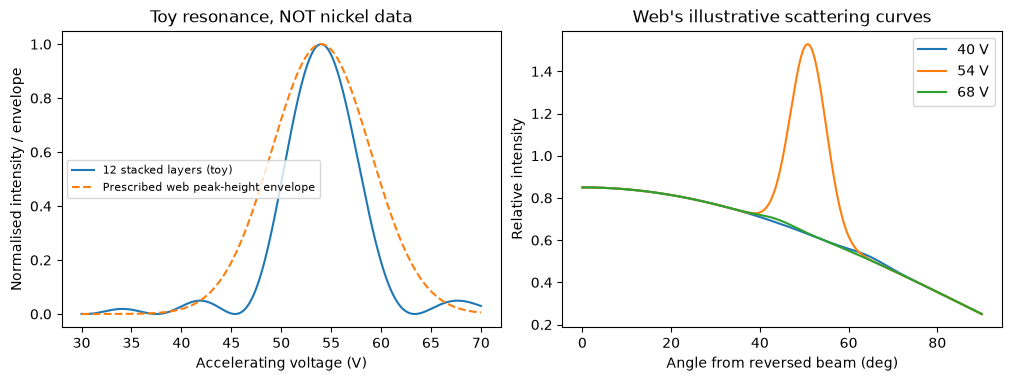

In [2]:
K = 12
theta0 = np.radians(theta54)
ell_nm = lam54 / (1 + np.cos(theta0))  # Chosen toy spacing, NOT measured Ni(111) spacing.
phase_step = 2 * np.pi * ell_nm * (1 + np.cos(theta0)) / wavelength_nm(voltage)
amplitude = np.exp(1j * phase_step[:, None] * np.arange(K)).mean(axis=1)
layer_intensity = np.abs(amplitude)**2
web_envelope = np.exp(-((voltage - 54) / 7)**2)
assert np.isclose(layer_intensity[np.argmin(abs(voltage - 54))], 1)
assert layer_intensity[0] < 0.1 and layer_intensity[-1] < 0.1
print(f"Chosen toy spacing = {ell_nm:.5f} nm; K = {K}; fixed angle = {theta54:.2f} deg")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
axes[0].plot(voltage, layer_intensity, label="12 stacked layers (toy)")
axes[0].plot(voltage, web_envelope, ls="--", label="Prescribed web peak-height envelope")
axes[0].set(xlabel="Accelerating voltage (V)", ylabel="Normalised intensity / envelope", title="Toy resonance, NOT nickel data")
axes[0].legend(fontsize=8)
angles = np.linspace(0, 90, 721)
for v in [40, 54, 68]:
    background = 0.25 + 0.6 * np.cos(np.radians(angles))
    intensity = background + 0.9 * np.exp(-((v - 54) / 7)**2) * np.exp(-(angles - peak_angle_deg(v))**2 / (2 * 4**2))
    axes[1].plot(angles, intensity, label=f"{v} V")
axes[1].set(xlabel="Angle from reversed beam (deg)", ylabel="Relative intensity", title="Web's illustrative scattering curves")
axes[1].legend()
plt.show()


## 3. Từng electron, rồi vân / Individual electrons, then fringes

Đặt $u=dx/(\lambda L)$, tức vị trí theo đơn vị khoảng vân. Với $a/d=0{,}25$, $E(u)=\mathrm{sinc}^2(\pi u a/d)$, trong đó $\mathrm{sinc}(x)=\sin x/x$:

- Hai khe: $I=E\cos^2(\pi u)$.
- Có máy dò khe (mất kết hợp): $I=E/2$.
- Một khe: $I=E/4$, cùng dạng nhưng chỉ một nửa số electron đến màn so với hai khe có máy dò.

*The which-slit detector removes the cross term. Blocking one slit halves throughput; rejection sampling gives positions conditional on arrival, so flux must be handled separately.*

Trên toàn trục, tổng cường độ hai khe bằng trường hợp máy dò. Cửa sổ hữu hạn $[-6,6]$ có sai khác nhỏ; chuẩn hoá trong cửa sổ khi lấy mẫu. Ở vùng xa, hai ảnh một khe chồng lên nhau trong xấp xỉ này.
*The both-slit and detector intensities have equal full-axis integrals. Our finite window introduces a small difference; normalise within it for sampling. The two incoherent single-slit envelopes overlap in this far-field approximation.*

Gợi lại Merli–Missiroli–Pozzi (1974; [bài xuất bản 1976](https://doi.org/10.1119/1.10184)) và [Tonomura và cộng sự (1989)](https://doi.org/10.1119/1.16104): các thí nghiệm đó dùng **biprism electron**, không phải tấm có hai khe vật lý. Mô hình khe đôi dưới đây minh hoạ sự tích luỹ xác suất, không tái dựng thiết bị ấy hoặc mô phỏng vi mô máy dò.
*Those experiments used electron biprisms. The two-slit model illustrates probability buildup rather than reproducing their apparatus or microscopic detection.*


Integrated intensities over [-6, 6]: {'both': 1.8617675382251067, 'detector': 1.8621831274268534, 'one': 0.9310915637134267}


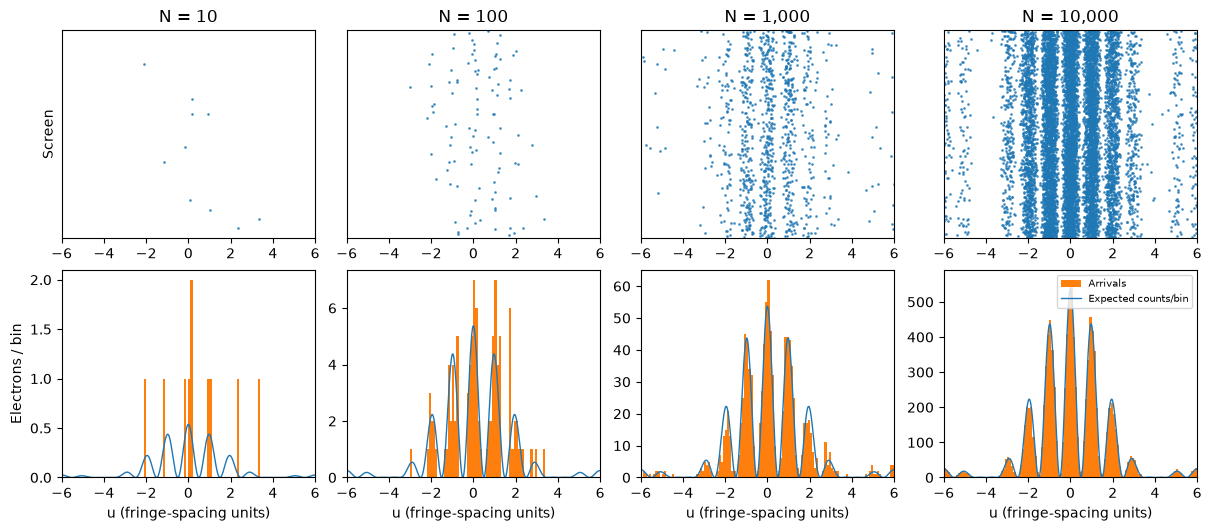

In [3]:
def two_slit(u, mode="both"):
    u = np.asarray(u)
    env = np.sinc(u * 0.25)**2  # NumPy sinc includes pi.
    return env * (np.cos(np.pi * u)**2 if mode == "both" else 0.5 if mode == "detector" else 0.25)

integrals = {mode: quad(lambda u: two_slit(u, mode), -6, 6, epsabs=1e-10)[0]
             for mode in ["both", "detector", "one"]}
assert two_slit(0, "both") == 1
assert two_slit(0.5, "both") < 1e-12
assert two_slit(0.5, "detector") > 0.1
assert abs(integrals["both"] / integrals["detector"] - 1) < 0.02
assert np.isclose(integrals["one"] / integrals["detector"], 0.5)
print("Integrated intensities over [-6, 6]:", integrals)

rng = np.random.default_rng(1927)
def sample_two_slit(n, mode="both"):
    accepted = []
    remaining = n
    ceiling = {"both": 1, "detector": 0.5, "one": 0.25}[mode]
    while remaining:
        candidates = rng.uniform(-6, 6, max(100, remaining * 5))
        selected = candidates[rng.random(len(candidates)) * ceiling < two_slit(candidates, mode)][:remaining]
        accepted.append(selected)
        remaining -= len(selected)
    return np.concatenate(accepted)

positions = sample_two_slit(10000)
vertical = rng.random(10000)
u = np.linspace(-6, 6, 2401)
fig, axes = plt.subplots(2, 4, figsize=(12, 5.2), layout="constrained")
for column, n in enumerate([10, 100, 1000, 10000]):
    axes[0, column].scatter(positions[:n], vertical[:n], s=1, color="tab:blue", alpha=0.7)
    axes[0, column].set(xlim=(-6, 6), ylim=(0, 1), title=f"N = {n:,}", yticks=[])
    axes[1, column].hist(positions[:n], bins=120, range=(-6, 6), color="tab:orange", label="Arrivals")
    axes[1, column].plot(u, n * 0.1 * two_slit(u) / integrals["both"], lw=1, label="Expected counts/bin")
    axes[1, column].set(xlim=(-6, 6), xlabel="u (fringe-spacing units)")
axes[0, 0].set_ylabel("Screen")
axes[1, 0].set_ylabel("Electrons / bin")
axes[1, -1].legend(fontsize=7)
plt.show()


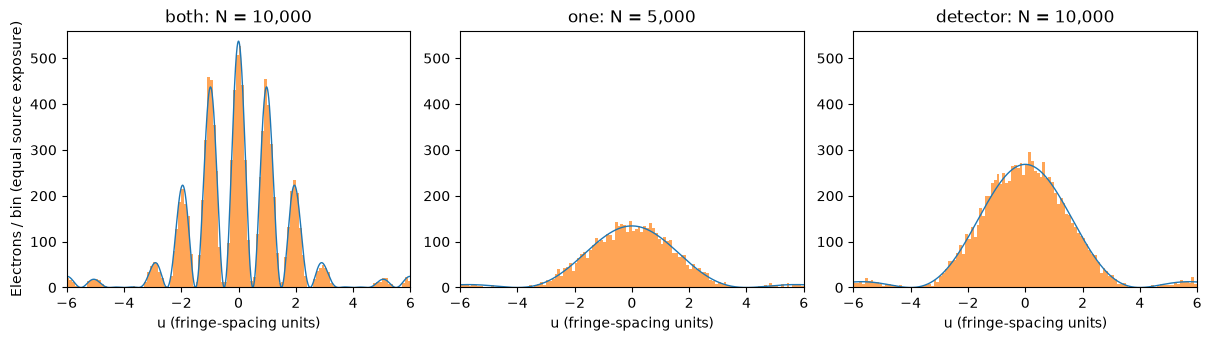

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), layout="constrained")
# Equal source exposure, rather than equal arrivals: one open slit gives half N.
for ax, mode, n in zip(axes, ["both", "one", "detector"], [10000, 5000, 10000]):
    samples = sample_two_slit(n, mode)
    assert np.all((-6 <= samples) & (samples <= 6))
    ax.hist(samples, bins=120, range=(-6, 6), color="tab:orange", alpha=0.7)
    ax.plot(u, n * 0.1 * two_slit(u, mode) / integrals[mode], color="tab:blue", lw=1)
    ax.set(xlim=(-6, 6), ylim=(0, 560), title=f"{mode}: N = {n:,}", xlabel="u (fringe-spacing units)")
axes[0].set_ylabel("Electrons / bin (equal source exposure)")
plt.show()


## 4. Vòng truyền qua màng: G. P. Thomson / Transmission rings: G. P. Thomson

[Thomson–Reid (1927)](https://doi.org/10.1038/119890a0) quan sát vòng khi electron truyền qua màng mỏng. Với màng đa tinh thể, các hạt tinh thể có mọi hướng tạo nón nhiễu xạ Debye–Scherrer; màn cắt nón thành vòng. Đặt $\beta$ là góc Bragg: $2d_{hkl}\sin\beta=\lambda$, góc tán xạ là $2\beta$, nên $R=L\tan(2\beta)\simeq L\lambda/d_{hkl}\propto V^{-1/2}$.
*Randomly oriented crystallites produce diffraction cones and hence rings. The scattering angle is twice the Bragg angle; at small angles ring radius scales with wavelength.*

Ở đây $d_{hkl}=0{,}20$ nm và $L=0{,}20$ m chỉ là ví dụ, không phải số đo gốc. Dùng 2–10 kV để xấp xỉ phi tương đối tính còn tốt (sai số bước sóng dưới 0,5%). Các khoảng cách trong hình nhiều vòng cũng là ví dụ.
*The spacings and camera length below are illustrative, not historical measurements. At 2–10 kV the nonrelativistic wavelength error is below 0.5%.*


Small-angle R(2 kV) / R(8 kV) = 2.000 (expected 2)


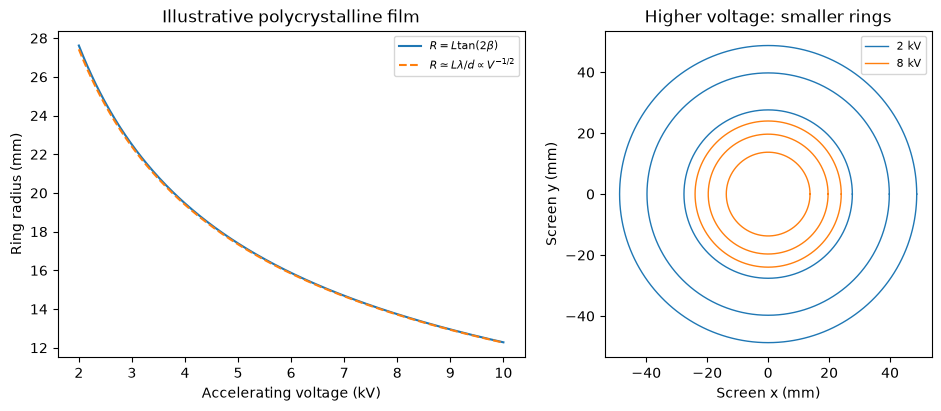

All wavelength, grating, intensity and ring-scaling checks passed.


In [5]:
from scipy.constants import c

voltage_rings = np.linspace(2000, 10000, 401)
L = 0.20
plane_spacing_nm = 0.20
lam = wavelength_nm(voltage_rings)
bragg = np.arcsin(lam / (2 * plane_spacing_nm))
radius_exact = L * np.tan(2 * bragg)
radius_small = L * lam / plane_spacing_nm
lam_rel = lam / np.sqrt(1 + e * voltage_rings / (2 * m_e * c**2))
assert np.max(abs(lam / lam_rel - 1)) < 0.005
assert np.allclose(radius_small * np.sqrt(voltage_rings), radius_small[0] * np.sqrt(voltage_rings[0]))
print(f"Small-angle R(2 kV) / R(8 kV) = {radius_small[0] / np.interp(8000, voltage_rings, radius_small):.3f} (expected 2)")
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].plot(voltage_rings / 1000, radius_exact * 1000, label=r"$R=L\tan(2\beta)$")
axes[0].plot(voltage_rings / 1000, radius_small * 1000, ls="--", label=r"$R\simeq L\lambda/d \propto V^{-1/2}$")
axes[0].set(xlabel="Accelerating voltage (kV)", ylabel="Ring radius (mm)", title="Illustrative polycrystalline film")
axes[0].legend(fontsize=8)
phi = np.linspace(0, 2 * np.pi, 721)
for v, color in [(2000, "tab:blue"), (8000, "tab:orange")]:
    for index, spacing in enumerate([0.20, 0.14, 0.115]):
        R = L * np.tan(2 * np.arcsin(wavelength_nm(v) / (2 * spacing))) * 1000
        axes[1].plot(R * np.cos(phi), R * np.sin(phi), color=color, lw=1,
                     label=f"{v / 1000:g} kV" if index == 0 else None)
axes[1].set(xlabel="Screen x (mm)", ylabel="Screen y (mm)", title="Higher voltage: smaller rings", aspect="equal")
axes[1].legend(fontsize=8)
plt.show()
print("All wavelength, grating, intensity and ring-scaling checks passed.")


## Nguồn / Sources

- C. Davisson & L. H. Germer, *Diffraction of Electrons by a Crystal of Nickel*, Physical Review **30**, 705–740 (1927), [doi:10.1103/PhysRev.30.705](https://doi.org/10.1103/PhysRev.30.705).
- P. G. Merli, G. F. Missiroli & G. Pozzi, *On the statistical aspect of electron interference phenomena*, American Journal of Physics **44**, 306–307 (1976; submitted 1974), [doi:10.1119/1.10184](https://doi.org/10.1119/1.10184).
- A. Tonomura et al., *Demonstration of single-electron buildup of an interference pattern*, American Journal of Physics **57**, 117–120 (1989), [doi:10.1119/1.16104](https://doi.org/10.1119/1.16104).
- G. P. Thomson & A. Reid, *Diffraction of Cathode Rays by a Thin Film*, Nature **119**, 890 (1927), [doi:10.1038/119890a0](https://doi.org/10.1038/119890a0).

Mọi đồ thị là phép tính hoặc mẫu Monte Carlo mới; không phải số liệu lịch sử gốc.
*All figures are new calculations or Monte Carlo samples, not historical raw data.*
